2/6: Loading CoreML model and detecting trees on ExG-segmented image...
Detected 1 valid trees (>= 70% size); filtered out 0 partial/half trees.
Detected 2 valid trees (>= 70% size); filtered out 0 partial/half trees.
Detected 3 valid trees (>= 70% size); filtered out 0 partial/half trees.
Detected 4 valid trees (>= 70% size); filtered out 0 partial/half trees.
Detected 5 valid trees (>= 70% size); filtered out 0 partial/half trees.
Detected 6 valid trees (>= 70% size); filtered out 0 partial/half trees.
Detected 7 valid trees (>= 70% size); filtered out 0 partial/half trees.
Detected 8 valid trees (>= 70% size); filtered out 0 partial/half trees.
Detected 9 valid trees (>= 70% size); filtered out 0 partial/half trees.
Detected 10 valid trees (>= 70% size); filtered out 0 partial/half trees.
Detected 11 valid trees (>= 70% size); filtered out 0 partial/half trees.
Detected 12 valid trees (>= 70% size); filtered out 0 partial/half trees.
Detected 13 valid trees (>= 70% size); filtered o

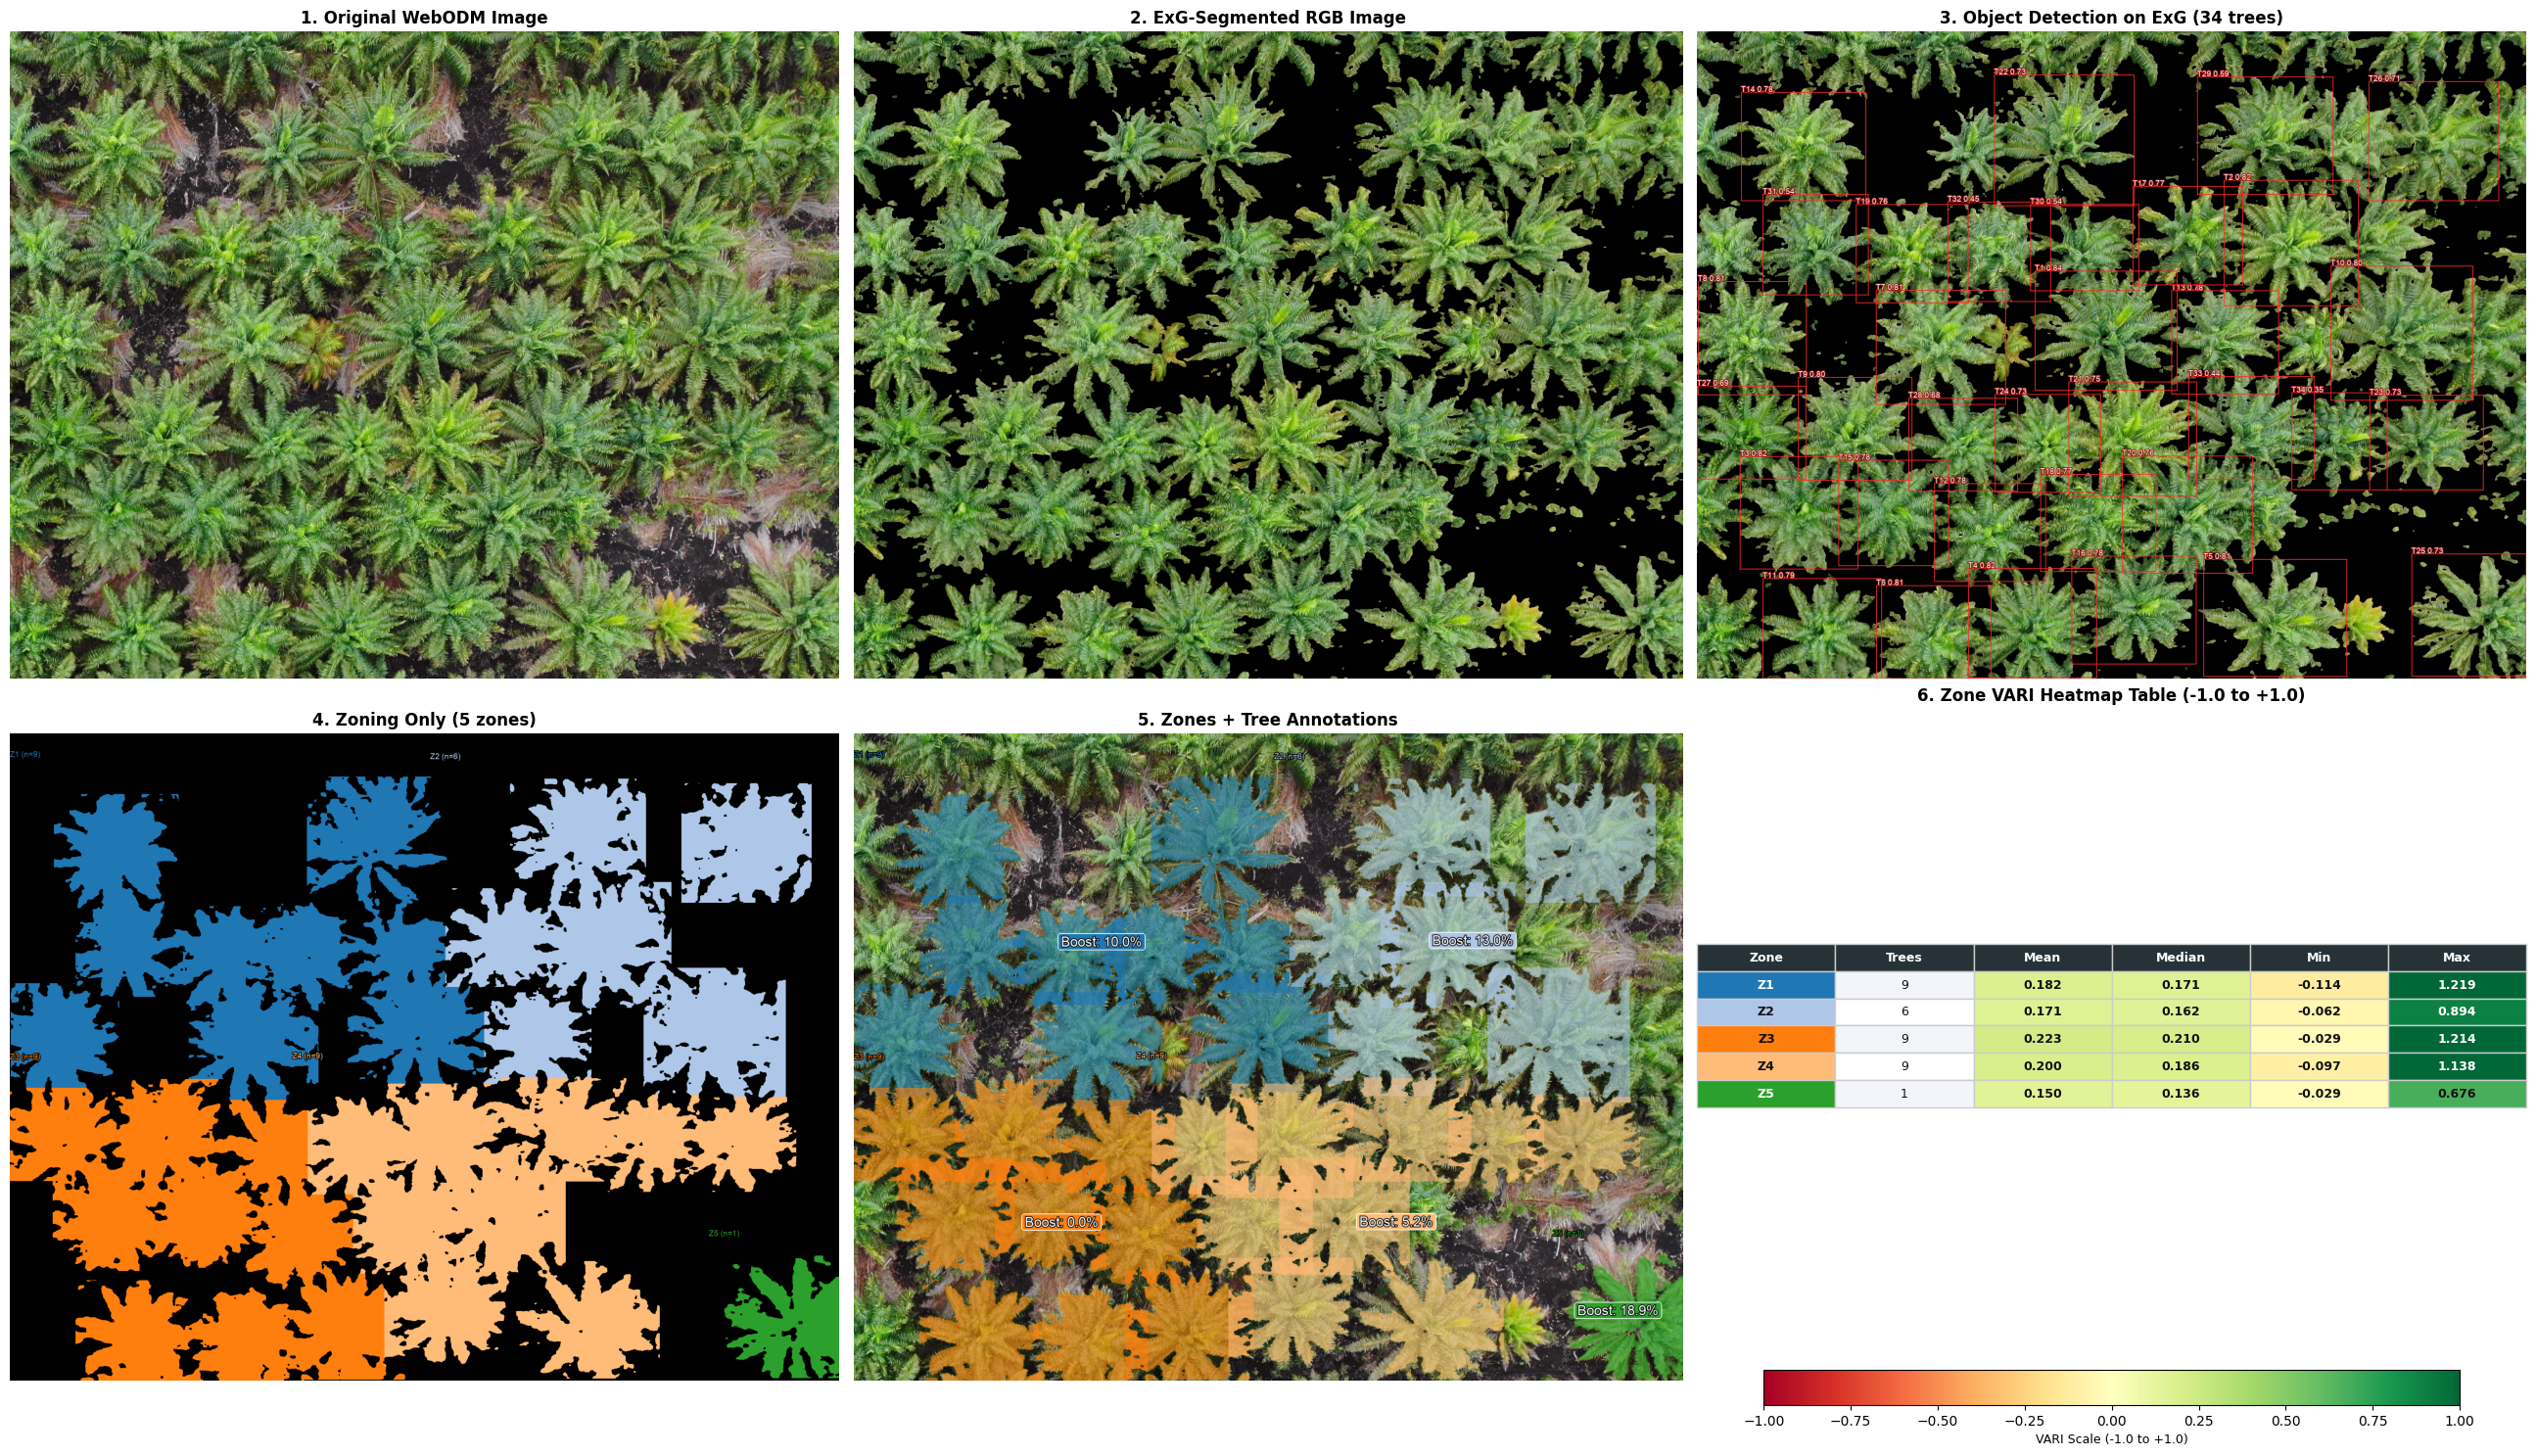

In [21]:
"""Oil-palm zoning + VARI analysis for a WebODM RGB image.
Pipeline:
1. ExG vegetation segmentation
2. CoreML object detection on the ExG-segmented image
3. Spatial grouping of detections into zones containing up to N trees
4. Annotated images for each stage (ExG RGB, CoreML on ExG, and Zones on Original)
5. VARI statistics per tree and per zone, using ExG vegetation pixels
6. JSON and CSV export with pixel and normalized coordinates
Run on macOS with coremltools and the required model installed.
"""
import csv
import json
from pathlib import Path
import coremltools as ct
import cv2
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image, ImageDraw, ImageFont
 # ------------------------- Configuration -------------------------
IMAGE_PATH = "dji_10.jpg"
MODEL_PATH = "yolo26m-krops-v0.1.mlpackage"
OUTPUT_JSON = "oil_palm_zones_vari.json"
OUTPUT_ZONE_CSV = "oil_palm_zone_vari_summary.csv"
OUTPUT_PRODUCT_MASS_CSV = "oil_palm_zone_fertilizer_product_mass.csv"
OUTPUT_EXG_MASK = "oil_palm_exg_mask.png"
OUTPUT_EXG_SEGMENTED = "oil_palm_exg_segmented.jpg"
OUTPUT_COREML_ANNOTATED = "oil_palm_coreml_detections.jpg"
OUTPUT_ZONE_ANNOTATED = "oil_palm_zones_only.jpg"
OUTPUT_ANNOTATED_IMAGE = "oil_palm_zones_annotated.jpg"
OUTPUT_PIPELINE_PLOT = "oil_palm_pipeline_stages.jpg"
CONF_THRESHOLD = 0.25
IOU_THRESHOLD = 0.45
MODEL_INPUT_SIZE = 640
ZONE_GRID_ROWS = 3
ZONE_GRID_COLS = 3
TREES_PER_ZONE = ZONE_GRID_ROWS * ZONE_GRID_COLS
ROW_TOLERANCE_MULTIPLIER = 0.75
MAX_ZONE_DISTANCE_MULTIPLIER = 3.0
ZONE_PADDING_MULTIPLIER = 0.15
MIN_TREE_COMPLETENESS = 0.70   # Keep only trees >= 70% of typical tree size/area*
BORDER_MARGIN_PX = 5
SHOW_PLOTS = True
# Illustrative maximum annual elemental nutrient rates (Mg or N) per hectare/year.
# Zone nutrient rates are B_i × these elemental rates. No product-content
# conversion is applied. Replace with approved nutrient targets.
FERTILIZER_MAX_NUTRIENT_RATES_KG_HA_PER_YEAR = {
    "kieserite": 100.0,
    "dolomite_alternative": None,  # cheaper Mg source; not a direct 1:1 substitute
    "ZA": 100.0,  # ammonium sulfate (zwavelzure ammoniak)
    "urea_alternative": None,  # higher-N alternative; not a direct 1:1 substitute
}
FERTILIZER_NUTRIENT_BY_PRODUCT = {
    "kieserite": "Mg", "dolomite_alternative": "Mg",
    "ZA": "N", "urea_alternative": "N",
}
# Optional elemental nutrient mass fractions from each actual product label.
# Enter, for example, 0.163 for a product containing 16.3% elemental Mg.
# Leave as None until verified from the product label. These are used only in
# the separate product-mass conversion output, never in the boost calculation.
FERTILIZER_PRODUCT_NUTRIENT_FRACTIONS = {
    # PDF specification states minimum 25.5% MgO; convert MgO to elemental Mg.
    "kieserite": 0.255 * (24.305 / 40.304),
    "dolomite_alternative": None,
    # PDF specification states 21% N, already expressed as elemental N.
    "ZA": 0.21,
    "urea_alternative": None,
}
# Optional costs are in a user-selected currency per kg of fertilizer product.
# Leave empty (or omit a product) to suppress cost outputs.
FERTILIZER_PRICE_PER_KG = {}
# Provide ground area per zone in hectares. Either use a JSON file such as
# {"1": 0.25, "2": 0.30}, or a uniform hectare value for every zone.
ZONE_AREA_HA_BY_ID = {}
ZONE_AREA_JSON_PATH = None
UNIFORM_ZONE_AREA_HA = None  # Optional override applied to every zone
# Default approximation from palm spacing. Midpoint of the supplied 9–11 m
# gap is 10 m, or 0.01 ha per palm. Zone area scales with detected tree count.
DEFAULT_TREE_SPACING_M = 10.0
USE_SPACING_BASED_ZONE_AREA_DEFAULT = True
# Replace the default after the upstream team supplies zone confidence values.
# Keys are zone IDs (as strings or integers); each value must be in [0.10, 1.0].
ZONE_CONFIDENCE_BY_ID = {}
DEFAULT_ZONE_CONFIDENCE = 0.60
 # -----------------------------------------------------------------
def iou(box1, box2):
    x1, y1 = max(box1[0], box2[0]), max(box1[1], box2[1])
    x2, y2 = min(box1[2], box2[2]), min(box1[3], box2[3])
    inter = max(0, x2 - x1) * max(0, y2 - y1)
    area1 = max(0, box1[2] - box1[0]) * max(0, box1[3] - box1[1])
    area2 = max(0, box2[2] - box2[0]) * max(0, box2[3] - box2[1])
    union = area1 + area2 - inter
    return inter / union if union > 0 else 0.0


def nms(boxes, scores, iou_threshold=0.45):
    if not boxes:
        return []
    order = np.argsort(scores)[::-1]
    selected = []
    while len(order) > 0:
        current = int(order[0])
        selected.append(current)
        order = np.asarray([
            int(j) for j in order[1:]
            if iou(boxes[current], boxes[int(j)]) <= iou_threshold
        ], dtype=int)
    return selected


def segment_vegetation_exg(image_bgr):
    """Create an ExG/Otsu mask. This is a heuristic vegetation mask, not a crown model."""
    b, g, r = cv2.split(image_bgr)
    exg = 2.0 * g.astype(np.float32) - r.astype(np.float32) - b.astype(np.float32)
    exg_u8 = cv2.normalize(exg, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
    _, mask = cv2.threshold(exg_u8, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    kernel = np.ones((3, 3), np.uint8)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel, iterations=1)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel, iterations=1)
    segmented = cv2.bitwise_and(image_bgr, image_bgr, mask=mask)
    return mask, segmented


def parse_coreml_predictions(model, rgb_image):
    """Parse the [1, 5, N] / [1, N, 5] single-class output assumed by the source script.
    Expected prediction rows: [cx, cy, width, height, confidence] in 640x640 pixels.
    """
    input_names = list(model.input_description)
    if not input_names:
        raise RuntimeError("The CoreML model has no declared input.")
    pil_image = Image.fromarray(rgb_image).convert("RGB").resize(
        (MODEL_INPUT_SIZE, MODEL_INPUT_SIZE)
    )
    prediction = model.predict({input_names[0]: pil_image})
    output_key = list(prediction.keys())[0]
    raw = np.asarray(prediction[output_key])
    raw = np.squeeze(raw)
    if raw.ndim != 2:
        raise ValueError(f"Unexpected model output shape {raw.shape}; expected a 2D array after squeeze.")
    if raw.shape[0] == 5:
        rows = raw.T
    elif raw.shape[1] == 5:
        rows = raw
    else:
        raise ValueError(
            f"Model output shape {raw.shape} does not have a 5-value detection axis. "
            "Inspect the CoreML output schema and update parse_coreml_predictions()."
        )
    boxes, scores = [], []
    for row in rows:
        cx, cy, width, height, confidence = map(float, row[:5])
        if not np.isfinite([cx, cy, width, height, confidence]).all() or confidence < CONF_THRESHOLD:
            continue
        box = [
            np.clip((cx - width / 2) / MODEL_INPUT_SIZE, 0, 1),
            np.clip((cy - height / 2) / MODEL_INPUT_SIZE, 0, 1),
            np.clip((cx + width / 2) / MODEL_INPUT_SIZE, 0, 1),
            np.clip((cy + height / 2) / MODEL_INPUT_SIZE, 0, 1),
        ]
        if box[2] > box[0] and box[3] > box[1]:
            boxes.append([float(v) for v in box])
            scores.append(confidence)
    keep = nms(boxes, scores, IOU_THRESHOLD)
    return [boxes[i] for i in keep], [scores[i] for i in keep]


def normalized_box_to_pixels(box, width, height):
    x1, y1, x2, y2 = box
    return [
        max(0, min(width, int(round(x1 * width)))),
        max(0, min(height, int(round(y1 * height)))),
        max(0, min(width, int(round(x2 * width)))),
        max(0, min(height, int(round(y2 * height)))),
    ]


def stats_for_box(vari_map, exg_mask, bbox):
    x1, y1, x2, y2 = bbox
    if x2 <= x1 or y2 <= y1:
        values = np.asarray([], dtype=np.float32)
    else:
        vari_crop = vari_map[y1:y2, x1:x2]
        mask_crop = exg_mask[y1:y2, x1:x2] > 0
        values = vari_crop[mask_crop & np.isfinite(vari_crop)]
    if values.size == 0:
        return {
            "vegetation_pixel_count": 0,
            "mean_vari": None,
            "median_vari": None,
            "std_vari": None,
            "mad_vari": None,
            "min_vari": None,
            "max_vari": None,
        }
    median = float(np.median(values))
    return {
        "vegetation_pixel_count": int(values.size),
        "mean_vari": float(np.mean(values)),
        "median_vari": median,
        "std_vari": float(np.std(values)),
        "mad_vari": float(np.median(np.abs(values - median))),
        "min_vari": float(np.min(values)),
        "max_vari": float(np.max(values)),
    }


def group_trees_into_zones(
    trees,
    grid_rows=3,
    grid_cols=3,
    row_tolerance_multiplier=0.75,
    max_zone_distance_multiplier=3.0,
    zone_padding_multiplier=0.15,
    image_width=None,
    image_height=None,
    ):
    """Group nearby palm trees into 3x3 spatial blocks (3 rows x 3 columns, up to 9 trees)."""
    if grid_rows < 1 or grid_cols < 1:
        raise ValueError("grid_rows and grid_cols must be at least 1.")
    if not trees:
        return []
    target_trees_per_zone = grid_rows * grid_cols
 # 1. Estimate typical tree size
    heights = [max(1, tree["bbox"][3] - tree["bbox"][1]) for tree in trees]
    median_height = float(np.median(heights))
    row_tolerance = max(1.0, median_height * row_tolerance_multiplier)
    max_zone_distance = max(1.0, median_height * max_zone_distance_multiplier)
    padding = max(0, int(median_height * zone_padding_multiplier))
 # 2. Cluster trees into approximate horizontal rows
    ordered = sorted(trees, key=lambda tree: (tree["center"][1], tree["center"][0]))
    rows = []
    for tree in ordered:
        cy = tree["center"][1]
        best_row = None
        best_distance = float("inf")
        for row in rows:
            row_center = float(np.median([item["center"][1] for item in row]))
            distance = abs(cy - row_center)
            if distance <= row_tolerance and distance < best_distance:
                best_row = row
                best_distance = distance
        if best_row is None:
            rows.append([tree])
        else:
            best_row.append(tree)
    rows.sort(key=lambda row: float(np.median([tree["center"][1] for tree in row])))
    for row in rows:
        row.sort(key=lambda tree: tree["center"][0])
 # 3. Group consecutive rows into bands of up to `grid_rows` (3 rows)
    row_bands = []
    current_band = []
    for row in rows:
        if not current_band:
            current_band.append(row)
        else:
            prev_row_y = float(np.median([t["center"][1] for t in current_band[-1]]))
            curr_row_y = float(np.median([t["center"][1] for t in row]))
            if len(current_band) >= grid_rows or (curr_row_y - prev_row_y) > max_zone_distance:
                row_bands.append(current_band)
                current_band = [row]
            else:
                current_band.append(row)
    if current_band:
        row_bands.append(current_band)
 # 4. Within each 3-row band, slice horizontally into 3-column blocks (up to 9 trees)
    zones = []
    for band_idx, band in enumerate(row_bands, start=1):
        band_trees = [tree for row in band for tree in row]
        band_trees.sort(key=lambda t: t["center"][0])
 # Split horizontally if there is a wide gap (e.g., road/clearing)
        spatial_clusters = []
        current_cluster = [band_trees[0]]
        for tree in band_trees[1:]:
            dx = tree["center"][0] - current_cluster[-1]["center"][0]
            if dx <= max_zone_distance:
                current_cluster.append(tree)
            else:
                spatial_clusters.append(current_cluster)
                current_cluster = [tree]
        spatial_clusters.append(current_cluster)
 # Slice each contiguous horizontal cluster into 3x3 blocks
        for cluster in spatial_clusters:
            block_capacity = len(band) * grid_cols   # 3 cols per row in the current band*
            for offset in range(0, len(cluster), block_capacity):
                members = cluster[offset:offset + block_capacity]
                x1 = min(t["bbox"][0] for t in members) - padding
                y1 = min(t["bbox"][1] for t in members) - padding
                x2 = max(t["bbox"][2] for t in members) + padding
                y2 = max(t["bbox"][3] for t in members) + padding
                if image_width is not None:
                    x1 = max(0, x1)
                    x2 = min(image_width, x2)
                if image_height is not None:
                    y1 = max(0, y1)
                    y2 = min(image_height, y2)
                zones.append({
                    "zone_id": len(zones) + 1,
                    "approx_row": band_idx,
                    "trees": members,
                    "bbox": [x1, y1, x2, y2],
                    "is_undersized": len(members) < target_trees_per_zone,
                })
    return zones


def pixel_bbox_record(bbox, image_width, image_height):
    x1, y1, x2, y2 = map(int, bbox)
    return {
        "x1": x1, "y1": y1, "x2": x2, "y2": y2,
        "width": x2 - x1,
        "height": y2 - y1,
        "normalized_xyxy": [
            x1 / image_width, y1 / image_height,
            x2 / image_width, y2 / image_height,
        ],
    }


def print_zone_vari_table(zone_json):
    """Print annual elemental nutrient boost quantities by zone."""
    headers = ["Zone", "Trees", "Mean VARI", "Boost rate"]
    products = [name for name, rate in FERTILIZER_MAX_NUTRIENT_RATES_KG_HA_PER_YEAR.items() if rate is not None]
    headers.extend(products)
    rows = []
    def fmt(value, digits=3):
        if value is None:
            return "N/A"
        if isinstance(value, (int, np.integer)):
            return f"{value:,}"
        if isinstance(value, (float, np.floating)):
            return f"{value:.{digits}f}" if np.isfinite(value) else "N/A"
        return str(value)
    for zone in zone_json:
        rec = zone.get("recommendation", {})
        boost = rec.get("boost_fraction")
        row = [f"Z{zone['zone_id']}", fmt(zone.get("tree_count")),
               fmt(zone.get("vari", {}).get("mean_vari")),
               f"{100 * boost:.1f}%" if boost is not None else "N/A"]
        for product in products:
            item = rec.get("fertilizers", {}).get(product, {})
            rate = item.get("boosted_rate_kg_ha_per_year")
            total = item.get("annual_total_kg")
            per_palm = item.get("kg_per_palm_per_year")
            nutrient = item.get("recommended_nutrient", "nutrient")
            row.append(f"{fmt(rate)} kg {nutrient}/ha/year; {fmt(total)} kg {nutrient}/zone/year; {fmt(per_palm)} kg {nutrient}/palm/year")
        rows.append(row)
    widths = [max(len(header), *(len(row[i]) for row in rows)) if rows else len(header)
              for i, header in enumerate(headers)]
    print("\n--- Zone Boost and Fertilizer Summary (annual) ---")
    print(" | ".join(header.ljust(widths[i]) for i, header in enumerate(headers)))
    print("-+-".join("-" * width for width in widths))
    if not rows:
        print("(No zones were created.)")
    else:
        for row in rows:
            print(" | ".join(value.ljust(widths[i]) for i, value in enumerate(row)))
    print("\nBoost calculation by zone:")
    print("  Vref = 95th percentile of valid zone mean VARI values")
    print("  B_i = max(0, 1 - V_i / Vref) × zone confidence")
    print("  Mg_i = B_i × Mg_max; N_i = B_i × N_max (kg elemental nutrient/ha/year)")
    print("  annual zone nutrient total = annual nutrient kg/ha × zone area (ha)")
    for zone in zone_json:
        rec = zone.get("recommendation", {})
        mean = zone.get("vari", {}).get("mean_vari")
        reference = rec.get("reference_zone_mean_vari")
        deficit = rec.get("vari_deficit_fraction")
        confidence = rec.get("zone_confidence")
        boost = rec.get("boost_fraction")
        if None in (mean, reference, deficit, confidence, boost) or reference <= 0:
            print(f"  Z{zone['zone_id']}: cannot calculate (missing/invalid VARI reference or zone mean)")
        else:
            print(f"  Z{zone['zone_id']}: V_i={mean:.3f}; Vref(P95)={reference:.3f}; "
                  f"B_i=max(0, 1 - {mean:.3f}/{reference:.3f}) × {confidence:.2f}={boost * 100:.1f}%")
        for product in FERTILIZER_MAX_NUTRIENT_RATES_KG_HA_PER_YEAR:
            item = rec.get("fertilizers", {}).get(product)
            if not item:
                continue
            nutrient = item["recommended_nutrient"]
            if boost is None:
                print(f"    {nutrient} from {product}: unavailable because zone boost could not be calculated")
                continue
            max_rate = item["base_rate_kg_ha_per_year"]
            annual_rate = item["boosted_rate_kg_ha_per_year"]
            zone_total = item["annual_total_kg"]
            area = rec.get("zone_area_ha")
            zone_text = f"{zone_total:.3f}" if zone_total is not None else "N/A"
            area_text = f"{area:.4f}" if area is not None else "N/A"
            rate_text = f"{annual_rate:.3f}" if annual_rate is not None else "N/A"
            print(f"    {nutrient} boost for {product}: B_i {boost * 100:.1f}% × max annual {nutrient} rate "
                  f"{max_rate:.3f} = {rate_text} kg {nutrient}/ha/year; zone total = "
                  f"{rate_text} × {area_text} ha = {zone_text} kg {nutrient}/zone/year")
    print("Values are annual elemental Mg or N rates and totals, not fertilizer product mass.")


def save_zone_vari_csv(zone_json, output_path):
    """Save one row per zone with VARI and fertilizer recommendation fields."""
    fieldnames = ["zone_id", "approx_row", "tree_count", "bbox_x1", "bbox_y1", "bbox_x2", "bbox_y2",
                  "vegetation_pixel_count", "mean_vari", "median_vari", "std_vari", "mad_vari", "min_vari", "max_vari",
                  "reference_zone_mean_vari", "zone_confidence", "vari_deficit_fraction", "boost_fraction", "zone_area_ha"]
    metrics = ("boost_added_rate_kg_ha_per_year", "boosted_rate_kg_ha_per_year",
               "annual_total_kg", "kg_per_palm_per_year")
    fieldnames += [f"{product}_{metric}" for product in FERTILIZER_MAX_NUTRIENT_RATES_KG_HA_PER_YEAR for metric in metrics]
    with open(output_path, "w", newline="", encoding="utf-8") as csv_file:
        writer = csv.DictWriter(csv_file, fieldnames=fieldnames)
        writer.writeheader()
        for zone in zone_json:
            bbox, stats = zone.get("bbox", {}), zone.get("vari", {})
            rec = zone.get("recommendation", {})
            row = {"zone_id": zone.get("zone_id"), "approx_row": zone.get("approx_row"),
                   "tree_count": zone.get("tree_count"), "bbox_x1": bbox.get("x1"), "bbox_y1": bbox.get("y1"),
                   "bbox_x2": bbox.get("x2"), "bbox_y2": bbox.get("y2"),
                   **{k: stats.get(k) for k in ("vegetation_pixel_count", "mean_vari", "median_vari", "std_vari", "mad_vari", "min_vari", "max_vari")},
                   **{k: rec.get(k) for k in ("reference_zone_mean_vari", "zone_confidence", "vari_deficit_fraction", "boost_fraction", "zone_area_ha")}}
            for product, item in rec.get("fertilizers", {}).items():
                for metric in metrics:
                    row[f"{product}_{metric}"] = item.get(metric)
            writer.writerow(row)


def build_and_print_product_mass_table(zone_json):
    """Separately convert annual elemental Mg/N targets to annual product mass."""
    rows = []
    print("\n--- Separate Fertilizer Product Mass Conversion (annual) ---")
    print("Uses product-label elemental nutrient fractions; boost and elemental outputs remain unchanged.")
    print("  Kieserite label: 25.5% MgO → elemental Mg fraction = 0.255 × (24.305/40.304).")
    print("  ZA label: 21% N → elemental N fraction = 0.210.")
    for zone in zone_json:
        rec = zone.get("recommendation", {})
        for product, max_nutrient_rate in FERTILIZER_MAX_NUTRIENT_RATES_KG_HA_PER_YEAR.items():
            if max_nutrient_rate is None:
                continue
            item = rec.get("fertilizers", {}).get(product, {})
            nutrient = item.get("recommended_nutrient", FERTILIZER_NUTRIENT_BY_PRODUCT[product])
            nutrient_zone_total = item.get("annual_total_kg")
            fraction = FERTILIZER_PRODUCT_NUTRIENT_FRACTIONS.get(product)
            if fraction is not None:
                fraction = float(fraction)
                if not np.isfinite(fraction) or not 0 < fraction <= 1:
                    raise ValueError(f"Product nutrient fraction for {product} must be greater than 0 and at most 1.")
            product_total = (nutrient_zone_total / fraction
                             if nutrient_zone_total is not None and fraction is not None else None)
            product_per_palm = (product_total / zone["tree_count"]
                                if product_total is not None and zone.get("tree_count", 0) > 0 else None)
            price = FERTILIZER_PRICE_PER_KG.get(product)
            rows.append({
                "zone_id": zone["zone_id"], "product": product, "nutrient": nutrient,
                "elemental_nutrient_kg_per_zone_per_year": nutrient_zone_total,
                "label_nutrient_fraction": fraction, "tree_count": zone.get("tree_count"),
                "product_kg_per_zone_per_year": product_total,
                "product_kg_per_palm_per_year": product_per_palm,
                **({"price_per_kg_product": float(price),
                    "annual_product_cost": product_total * float(price) if product_total is not None else None}
                   if price is not None else {}),
            })
    headers = ["Zone", "Product", "Nutrient target kg/zone/year", "Label fraction", "Product kg/zone/year", "Trees", "Product kg/palm/year"]
    if any(FERTILIZER_PRICE_PER_KG.get(p) is not None for p in FERTILIZER_MAX_NUTRIENT_RATES_KG_HA_PER_YEAR):
        headers.append("Annual product cost")
    def fmt(value):
        return "N/A" if value is None else f"{value:.4f}"
    display = []
    for r in rows:
        line = [f"Z{r['zone_id']}", r["product"], fmt(r["elemental_nutrient_kg_per_zone_per_year"]),
                fmt(r["label_nutrient_fraction"]), fmt(r["product_kg_per_zone_per_year"]),
                str(r["tree_count"]), fmt(r["product_kg_per_palm_per_year"])]
        if "annual_product_cost" in r:
            line.append(fmt(r["annual_product_cost"]))
        display.append(line)
    widths = [max(len(h), *(len(r[i]) for r in display)) if display else len(h) for i, h in enumerate(headers)]
    print(" | ".join(h.ljust(widths[i]) for i, h in enumerate(headers)))
    print("-+-".join("-" * w for w in widths))
    if not display:
        print("(No active fertilizer products.)")
    else:
        for row in display:
            print(" | ".join(v.ljust(widths[i]) for i, v in enumerate(row)))
    print("\nProduct mass calculations:")
    print("  product kg/zone/year = elemental nutrient kg/zone/year ÷ product-label nutrient fraction")
    print("  product kg/palm/year = product kg/zone/year ÷ tree count")
    for row in rows:
        target, fraction = row["elemental_nutrient_kg_per_zone_per_year"], row["label_nutrient_fraction"]
        if target is None or fraction is None:
            print(f"  Z{row['zone_id']} {row['product']}: enter its verified label fraction to calculate product mass")
        else:
            print(f"  Z{row['zone_id']} {row['product']}: {target:.4f} kg {row['nutrient']}/zone/year ÷ {fraction:.4f}"
                  f" = {row['product_kg_per_zone_per_year']:.4f} kg product/zone/year")
            if row.get("annual_product_cost") is not None:
                print(f"    annual product cost = {row['product_kg_per_zone_per_year']:.4f} kg × "
                      f"{row['price_per_kg_product']:.4f}/kg = {row['annual_product_cost']:.4f}")
    return rows


def save_product_mass_csv(rows, output_path):
    """Save product-mass conversions separately from the elemental zone CSV."""
    fields = ["zone_id", "product", "nutrient", "elemental_nutrient_kg_per_zone_per_year",
              "label_nutrient_fraction", "tree_count",
              "product_kg_per_zone_per_year", "product_kg_per_palm_per_year"]
    if any(FERTILIZER_PRICE_PER_KG.get(p) is not None for p in FERTILIZER_MAX_NUTRIENT_RATES_KG_HA_PER_YEAR):
        fields.extend(["price_per_kg_product", "annual_product_cost"])
    with open(output_path, "w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=fields)
        writer.writeheader()
        writer.writerows(rows)


def load_zone_areas():
    """Return supplied ground area in hectares by zone ID; never infer from pixels."""
    areas = {str(k): float(v) for k, v in ZONE_AREA_HA_BY_ID.items()}
    if ZONE_AREA_JSON_PATH:
        with open(ZONE_AREA_JSON_PATH, "r", encoding="utf-8") as f:
            loaded = json.load(f)
        if not isinstance(loaded, dict):
            raise ValueError("ZONE_AREA_JSON_PATH must contain a JSON object mapping zone IDs to hectares.")
        areas.update({str(k): float(v) for k, v in loaded.items()})
    if UNIFORM_ZONE_AREA_HA is not None:
        if float(UNIFORM_ZONE_AREA_HA) <= 0:
            raise ValueError("UNIFORM_ZONE_AREA_HA must be positive.")
    for key, value in areas.items():
        if not np.isfinite(value) or value <= 0:
            raise ValueError(f"Area for zone {key} must be a finite positive number of hectares.")
    return areas


def add_zone_boost_and_fertilizer(zone_json):
    """Attach annual VARI-relative elemental nutrient targets by zone."""
    valid_means = [z["vari"].get("mean_vari") for z in zone_json
                   if z.get("vari", {}).get("mean_vari") is not None
                   and np.isfinite(z["vari"]["mean_vari"])]
    reference = float(np.percentile(valid_means, 95)) if valid_means else None
    areas = load_zone_areas()
    products = FERTILIZER_MAX_NUTRIENT_RATES_KG_HA_PER_YEAR
    for product, rate in products.items():
        if rate is not None and (not np.isfinite(float(rate)) or float(rate) < 0):
            raise ValueError(f"Annual elemental rate for {product} must be nonnegative or None.")
        price = FERTILIZER_PRICE_PER_KG.get(product)
        if price is not None and (not np.isfinite(float(price)) or float(price) < 0):
            raise ValueError(f"Product price for {product} must be nonnegative.")
    for zone in zone_json:
        zid = str(zone["zone_id"])
        confidence = float(ZONE_CONFIDENCE_BY_ID.get(zid, ZONE_CONFIDENCE_BY_ID.get(zone["zone_id"], DEFAULT_ZONE_CONFIDENCE)))
        if not np.isfinite(confidence) or not 0.10 <= confidence <= 1.0:
            raise ValueError(f"Confidence for zone {zid} must be in the range 0.10 to 1.0.")
        mean = zone.get("vari", {}).get("mean_vari")
        if reference is None or reference <= 0 or mean is None or not np.isfinite(mean):
            deficit = boost = None
        else:
            deficit = max(0.0, 1.0 - float(mean) / reference)
            boost = deficit * confidence
        if zid in areas:
            area = areas[zid]
        elif UNIFORM_ZONE_AREA_HA is not None:
            area = float(UNIFORM_ZONE_AREA_HA)
        elif USE_SPACING_BASED_ZONE_AREA_DEFAULT:
            if DEFAULT_TREE_SPACING_M <= 0:
                raise ValueError("DEFAULT_TREE_SPACING_M must be positive.")
            area = zone.get("tree_count", 0) * (DEFAULT_TREE_SPACING_M ** 2) / 10000.0
        else:
            area = None
        recommendation = {
            "reference_zone_mean_vari": reference,
            "reference_zone_mean_vari_percentile": 95,
            "zone_confidence": confidence,
            "vari_deficit_fraction": deficit,
            "boost_fraction": boost,
            "zone_area_ha": area,
            "fertilizers": {},
            "area_note": ("Approximate area from detected tree count × spacing²; default spacing is 10 m (midpoint of 9–11 m). Replace with measured zone areas when available."
                          if USE_SPACING_BASED_ZONE_AREA_DEFAULT and zid not in areas and UNIFORM_ZONE_AREA_HA is None
                          else (None if area is not None else "Provide zone ground area in hectares; pixel dimensions are not converted to area.")),
        }
        for product, max_nutrient_rate in products.items():
            if max_nutrient_rate is None:
                continue
            nutrient = FERTILIZER_NUTRIENT_BY_PRODUCT.get(product)
            if nutrient not in ("Mg", "N"):
                raise ValueError(f"Set FERTILIZER_NUTRIENT_BY_PRODUCT for {product} to 'Mg' or 'N'.")
            annual_rate = float(max_nutrient_rate) * boost if boost is not None else None
            annual_total = annual_rate * area if area is not None and annual_rate is not None else None
            item = {
                "base_rate_kg_ha_per_year": float(max_nutrient_rate),
                "boost_added_rate_kg_ha_per_year": annual_rate,
                "boosted_rate_kg_ha_per_year": annual_rate,
                "recommended_nutrient": nutrient,
                "recommended_nutrient_kg_ha_per_year": annual_rate,
                "annual_total_kg": annual_total,
                "kg_per_palm_per_year": annual_total / zone["tree_count"]
                    if annual_total is not None and zone.get("tree_count", 0) > 0 else None,
            }
            item[f"{nutrient.lower()}_kg_ha_per_year"] = annual_rate
            item[f"{nutrient.lower()}_total_kg_per_year"] = annual_total
            recommendation["fertilizers"][product] = item
        zone["recommendation"] = recommendation
    return reference


def main():
    import matplotlib.cm as cm
    import matplotlib.colors as mcolors
    image_path = Path(IMAGE_PATH)
    model_path = Path(MODEL_PATH)
    if not image_path.exists():
        raise FileNotFoundError(f"Image not found: {image_path.resolve()}")
    if not model_path.exists():
        raise FileNotFoundError(f"CoreML model not found: {model_path.resolve()}")
        print("1/6: Loading image and running ExG segmentation...")
    original_bgr = cv2.imread(str(image_path), cv2.IMREAD_COLOR)
    if original_bgr is None:
        raise ValueError(f"Could not read image: {image_path}")
    height, width = original_bgr.shape[:2]
    original_rgb = cv2.cvtColor(original_bgr, cv2.COLOR_BGR2RGB)
    exg_mask, segmented_bgr = segment_vegetation_exg(original_bgr)
    segmented_rgb = cv2.cvtColor(segmented_bgr, cv2.COLOR_BGR2RGB)
    cv2.imwrite(OUTPUT_EXG_MASK, exg_mask)
    cv2.imwrite(OUTPUT_EXG_SEGMENTED, segmented_bgr)
    print("2/6: Loading CoreML model and detecting trees on ExG-segmented image...")
    model = ct.models.MLModel(str(model_path))
    normalized_boxes, scores = parse_coreml_predictions(model, segmented_rgb)
    raw_trees = []
    for box, score in zip(normalized_boxes, scores):
        bbox = normalized_box_to_pixels(box, width, height)
        bw, bh = bbox[2] - bbox[0], bbox[3] - bbox[1]
        if bw <= 0 or bh <= 0:
            continue
        raw_trees.append({
            "confidence": float(score),
            "bbox": bbox,
            "width": bw,
            "height": bh,
            "area": bw * bh,
            "center": ((bbox[0] + bbox[2]) / 2.0, (bbox[1] + bbox[3]) / 2.0),
            "bbox_normalized": [bbox[0] / width, bbox[1] / height, bbox[2] / width, bbox[3] / height],
        })
 # Reference full-tree size from interior trees (not clipped by image borders)
    interior_trees = [
        t for t in raw_trees
        if t["bbox"][0] > BORDER_MARGIN_PX
        and t["bbox"][1] > BORDER_MARGIN_PX
        and t["bbox"][2] < (width - BORDER_MARGIN_PX)
        and t["bbox"][3] < (height - BORDER_MARGIN_PX)
    ]
    ref_pool = interior_trees if interior_trees else raw_trees
    if ref_pool:
        median_w = float(np.median([t["width"] for t in ref_pool]))
        median_h = float(np.median([t["height"] for t in ref_pool]))
        median_area = float(np.median([t["area"] for t in ref_pool]))
    else:
        median_w = median_h = median_area = 0.0
 # Keep only trees that are at least 70% of typical width, height, and area
    trees = []
    skipped_partial = 0
    for t in raw_trees:
        w_ratio = t["width"] / median_w if median_w > 0 else 1.0
        h_ratio = t["height"] / median_h if median_h > 0 else 1.0
        area_ratio = t["area"] / median_area if median_area > 0 else 1.0
        if (
            w_ratio < MIN_TREE_COMPLETENESS
            or h_ratio < MIN_TREE_COMPLETENESS
            or area_ratio < MIN_TREE_COMPLETENESS
        ):
            skipped_partial += 1
            continue
        t["tree_id"] = len(trees) + 1
        trees.append(t)
        print(
        f"Detected {len(trees)} valid trees (>= {int(MIN_TREE_COMPLETENESS * 100)}% size); "
        f"filtered out {skipped_partial} partial/half trees."
    )
    print("3/6: Calculating VARI map and tree-level statistics...")
    b, g, r = cv2.split(original_bgr)
    b = b.astype(np.float32)
    g = g.astype(np.float32)
    r = r.astype(np.float32)
    denominator = g + r - b
    vari_map = np.full((height, width), np.nan, dtype=np.float32)
    valid = np.isfinite(denominator) & (np.abs(denominator) > 1e-6)
    np.divide(g - r, denominator, out=vari_map, where=valid)
    for tree in trees:
        tree["vari"] = stats_for_box(vari_map, exg_mask, tree["bbox"])
        tree["bbox_annotation"] = pixel_bbox_record(tree["bbox"], width, height)
        print(f"4/6: Grouping trees into {ZONE_GRID_ROWS}x{ZONE_GRID_COLS} zones (up to {TREES_PER_ZONE} trees/zone)...")
    zones = group_trees_into_zones(
        trees,
        grid_rows=ZONE_GRID_ROWS,
        grid_cols=ZONE_GRID_COLS,
        row_tolerance_multiplier=ROW_TOLERANCE_MULTIPLIER,
        max_zone_distance_multiplier=MAX_ZONE_DISTANCE_MULTIPLIER,
        zone_padding_multiplier=ZONE_PADDING_MULTIPLIER,
        image_width=width,
        image_height=height,
    )
    print("5/6: Coloring ExG tree masks by zone and calculating zone statistics...")
    try:
        font = ImageFont.truetype("Arial.ttf", max(12, min(24, width // 100)))
    except OSError:
        font = ImageFont.load_default()
    tree_line_width = max(2, width // 1500)
    MASK_OVERLAY_ALPHA = 0.60
 # Image 3: CoreML object detections drawn on the ExG-segmented RGB image
    coreml_on_exg_img = Image.fromarray(segmented_rgb.copy())
    draw_coreml_exg = ImageDraw.Draw(coreml_on_exg_img)
    for tree in trees:
        tb = tree["bbox"]
        draw_coreml_exg.rectangle(tb, outline=(255, 40, 40), width=tree_line_width)
        tree_label = f"T{tree['tree_id']} {tree['confidence']:.2f}"
        tx, ty = tb[0], max(0, tb[1] - 18)
        draw_coreml_exg.text(
            (tx, ty), tree_label,
            fill=(255, 255, 255), stroke_width=2, stroke_fill=(150, 0, 0), font=font
        )
    coreml_on_exg_img.save(OUTPUT_COREML_ANNOTATED, quality=95)
 # Image 4a: Black canvas where ONLY detected tree ExG mask pixels are colored by Zone ID
    zone_tree_mask_rgb = np.zeros_like(original_rgb)
 # Image 4b: Original WebODM image where detected tree ExG mask pixels are blended by Zone ID
    zone_tree_overlay_rgb = original_rgb.copy()
    cmap_zones = plt.colormaps["tab20"]
    zone_label_positions = []
    zone_json = []
    for zone in zones:
        zb = zone["bbox"]
        zx1, zy1, zx2, zy2 = zb
        tree_records = []
 # Pick a unique RGB color for this zone
        rgba = cmap_zones((zone["zone_id"] - 1) % 20 / 20.0)
        zone_color_u8 = np.array([int(round(c * 255)) for c in rgba[:3]], dtype=np.uint8)
        zone_color = tuple(int(v) for v in zone_color_u8)
 # Union mask of member tree boxes so Zone VARI only uses member tree ExG pixels
        tree_box_union = np.zeros((zy2 - zy1, zx2 - zx1), dtype=bool)
        for tree in zone["trees"]:
            tx1, ty1, tx2, ty2 = tree["bbox"]
            tree_records.append({
                "tree_id": tree["tree_id"],
                "confidence": tree["confidence"],
                "bbox": tree["bbox_annotation"],
                "vari": tree["vari"],
            })
 # Get ExG mask pixels inside this tree's detection area
            tree_exg_mask = exg_mask[ty1:ty2, tx1:tx2] > 0
 # 1) Color the tree's ExG mask pixels on the black canvas
            zone_tree_mask_rgb[ty1:ty2, tx1:tx2][tree_exg_mask] = zone_color_u8
 # 2) Alpha-blend the zone color onto the tree's ExG mask pixels on the original image
            orig_crop = zone_tree_overlay_rgb[ty1:ty2, tx1:tx2]
            orig_crop[tree_exg_mask] = (
                orig_crop[tree_exg_mask].astype(np.float32) * (1.0 - MASK_OVERLAY_ALPHA)
                + zone_color_u8.astype(np.float32) * MASK_OVERLAY_ALPHA
            ).astype(np.uint8)
 # Mark this tree's region inside the zone union mask
            lx1, ly1 = max(0, tx1 - zx1), max(0, ty1 - zy1)
            lx2, ly2 = min(zx2 - zx1, tx2 - zx1), min(zy2 - zy1, ty2 - zy1)
            if lx2 > lx1 and ly2 > ly1:
                tree_box_union[ly1:ly2, lx1:lx2] = True
 # Calculate Zone VARI strictly from the colored ExG tree pixels in this zone
        vari_crop = vari_map[zy1:zy2, zx1:zx2]
        mask_crop = (exg_mask[zy1:zy2, zx1:zx2] > 0) & tree_box_union
        valid_vals = vari_crop[mask_crop & np.isfinite(vari_crop)]
        if valid_vals.size == 0:
            zone_stats = {
                "vegetation_pixel_count": 0,
                "mean_vari": None, "median_vari": None,
                "std_vari": None, "mad_vari": None,
                "min_vari": None, "max_vari": None,
            }
        else:
            med = float(np.median(valid_vals))
            zone_stats = {
                "vegetation_pixel_count": int(valid_vals.size),
                "mean_vari": float(np.mean(valid_vals)),
                "median_vari": med,
                "std_vari": float(np.std(valid_vals)),
                "mad_vari": float(np.median(np.abs(valid_vals - med))),
                "min_vari": float(np.min(valid_vals)),
                "max_vari": float(np.max(valid_vals)),
            }
        zone_label = f"Z{zone['zone_id']} (n={len(tree_records)})"
        zx, zy = zx1, max(0, zy1 - 28)
        zone_label_positions.append((zx, zy, zone_label, zone_color))
        zone_json.append({
            "zone_id": zone["zone_id"],
            "approx_row": zone["approx_row"],
            "tree_count": len(tree_records),
            "bbox": pixel_bbox_record(zb, width, height),
            "vari": zone_stats,
            "trees": tree_records,
        })
    reference_mean = add_zone_boost_and_fertilizer(zone_json)
    zones_only_img = Image.fromarray(zone_tree_mask_rgb)
    draw_zones_only = ImageDraw.Draw(zones_only_img)
    combined_annotated_img = Image.fromarray(zone_tree_overlay_rgb)
    draw_combined = ImageDraw.Draw(combined_annotated_img)
 # Draw only the Zone ID text labels (no bounding boxes)
    for zx, zy, zone_label, zone_color in zone_label_positions:
        for canvas in (draw_zones_only, draw_combined):
            canvas.text(
                (zx, zy), zone_label,
                fill=zone_color, stroke_width=2, stroke_fill=(0, 0, 0), font=font
            )
    # Center the calculated boost percentage over each zone on the combined
    # zones + tree annotations image. Boost is computed after VARI aggregation.
    boost_font_size = max(16, min(36, width // 60))
    try:
        boost_font = ImageFont.truetype("Arial.ttf", boost_font_size)
    except OSError:
        boost_font = ImageFont.load_default()
    for zone, zone_color in zip(zone_json, [
        tuple(int(round(c * 255)) for c in cmap_zones((z["zone_id"] - 1) % 20 / 20.0)[:3])
        for z in zones
    ]):
        boost = zone.get("recommendation", {}).get("boost_fraction")
        boost_text = f"Boost: {boost * 100:.1f}%" if boost is not None else "Boost: N/A"
        box = zone["bbox"]
        center = ((box["x1"] + box["x2"]) // 2, (box["y1"] + box["y2"]) // 2)
        text_box = draw_combined.textbbox(center, boost_text, font=boost_font, anchor="mm", stroke_width=2)
        pad = max(5, boost_font_size // 5)
        draw_combined.rounded_rectangle(
            (text_box[0] - pad, text_box[1] - pad, text_box[2] + pad, text_box[3] + pad),
            radius=max(4, pad), fill=zone_color, outline=(255, 255, 255), width=2,
        )
        draw_combined.text(
            center, boost_text, fill=(255, 255, 255), font=boost_font, anchor="mm",
            stroke_width=2, stroke_fill=(0, 0, 0),
        )
    zones_only_img.save(OUTPUT_ZONE_ANNOTATED, quality=95)
    combined_annotated_img.save(OUTPUT_ANNOTATED_IMAGE, quality=95)
    # Save CSV and print summary table
    save_zone_vari_csv(zone_json, OUTPUT_ZONE_CSV)
    print_zone_vari_table(zone_json)
    product_mass_rows = build_and_print_product_mass_table(zone_json)
    save_product_mass_csv(product_mass_rows, OUTPUT_PRODUCT_MASS_CSV)
    # Save JSON
    result = {
        "metadata": {
            "source_image": str(image_path),
            "image_width_px": width,
            "image_height_px": height,
            "exg_method": "ExG = 2G - R - B; min-max normalized; Otsu threshold; 3x3 opening/closing",
            "vari_formula": "(G - R) / (G + R - B)",
            "zone_boost_formula": "Bi=max(0, 1-Vi/Vref)*confidence; Vref=95th percentile of valid zone mean VARI",
            "fertilizer_boost_formula": "Mg_i=Bi*Mg_max; N_i=Bi*N_max; annual zone nutrient kg=annual nutrient kg/ha*zone area ha",
            "reference_zone_mean_vari": reference_mean,
            "zone_confidence_default": DEFAULT_ZONE_CONFIDENCE,
            "max_elemental_nutrient_rates_kg_ha_per_year": FERTILIZER_MAX_NUTRIENT_RATES_KG_HA_PER_YEAR,
            "fertilizer_nutrient_by_product": FERTILIZER_NUTRIENT_BY_PRODUCT,
            "fertilizer_product_nutrient_fractions": FERTILIZER_PRODUCT_NUTRIENT_FRACTIONS,
            "fertilizer_prices_per_kg": FERTILIZER_PRICE_PER_KG,
            "ground_area_source": "user-supplied mapping/uniform area when provided; otherwise estimated as detected tree count × 10 m × 10 m, not from image pixels",
            "vari_pixel_filter": "Only finite VARI pixels with non-zero denominator inside ExG mask are included",
            "model_path": str(model_path),
            "confidence_threshold": CONF_THRESHOLD,
            "nms_iou_threshold": IOU_THRESHOLD,
            "trees_per_zone_max": TREES_PER_ZONE,
            "zone_grouping": "Approximate image-row clustering, then left-to-right chunks; each zone is the rectangle enclosing its member tree boxes",
            "row_tolerance_multiplier": ROW_TOLERANCE_MULTIPLIER,
            "detected_tree_count": len(trees),
            "zone_count": len(zone_json),
            "coordinate_system": "Pixel coordinates use origin (0,0) at top-left; bbox x1,y1 inclusive-ish and x2,y2 exclusive crop boundary. normalized_xyxy values are divided by original image width/height.",
            "limitations": [
                "ExG is a heuristic vegetation mask and may include weeds or omit shaded palm leaves.",
                "Zone rectangles are generated from spatial grouping of detected trees; they are not guaranteed to match actual plantation blocks or planting rows.",
                "Zone VARI summarizes the entire rectangular zone's ExG-selected pixels, which may include vegetation between tree boxes. Use tree-only aggregation instead if that is the intended zone definition.",
                "VARI is an RGB vegetation index, not a direct diagnosis of palm health or fertilizer requirement.",
                "Fertilizer rates and prices are illustrative/configurable and are not agronomic recommendations.",
                "Reported fertilizer boosts and totals are elemental Mg or N quantities; they are not converted to product mass.",
                "Ground zone areas are not derived from image pixels. If measured areas are not supplied, fertilizer quantities use an approximate 10 m palm spacing (0.01 ha per detected palm); actual zone area may differ.",
            ],
        },
        "zones": zone_json,
        "fertilizer_product_mass_conversions": product_mass_rows,
    }
    with open(OUTPUT_JSON, "w", encoding="utf-8") as f:
        json.dump(result, f, indent=2, ensure_ascii=False, allow_nan=False)
 # Build and save the 2x3 visualization figure (5 images + 1 VARI Heatmap Table)
    fig, axes = plt.subplots(2, 3, figsize=(26, 15))
    axes[0][0].imshow(original_rgb)
    axes[0][0].set_title("1. Original WebODM Image", fontsize=12, fontweight="bold")
    axes[0][0].axis("off")
    axes[0][1].imshow(segmented_rgb)
    axes[0][1].set_title("2. ExG-Segmented RGB Image", fontsize=12, fontweight="bold")
    axes[0][1].axis("off")
    axes[0][2].imshow(coreml_on_exg_img)
    axes[0][2].set_title(f"3. Object Detection on ExG ({len(trees)} trees)", fontsize=12, fontweight="bold")
    axes[0][2].axis("off")
    axes[1][0].imshow(zones_only_img)
    axes[1][0].set_title(f"4. Zoning Only ({len(zones)} zones)", fontsize=12, fontweight="bold")
    axes[1][0].axis("off")
    axes[1][1].imshow(combined_annotated_img)
    axes[1][1].set_title("5. Zones + Tree Annotations", fontsize=12, fontweight="bold")
    axes[1][1].axis("off")
 # 6th Panel: Zone VARI Heatmap Table (-1.0 to +1.0)
    ax_table = axes[1][2]
    ax_table.axis("off")
    ax_table.set_title("6. Zone VARI Heatmap Table (-1.0 to +1.0)", fontsize=12, fontweight="bold")
    if zone_json:
        cmap_vari = plt.colormaps["RdYlGn"]
        norm_vari = mcolors.Normalize(vmin=-1.0, vmax=1.0)
        col_labels = ["Zone", "Trees", "Mean", "Median", "Min", "Max"]
        heatmap_cols = {2, 3, 4, 5}
        cell_text, cell_colors, text_colors = [], [], []
        for r_idx, z in enumerate(zone_json):
            st = z.get("vari", {})
            vals = [st.get("mean_vari"), st.get("median_vari"), st.get("min_vari"), st.get("max_vari")]
            row_str = [
                f"Z{z['zone_id']}",
                str(z["tree_count"]),
                *[f"{v:.3f}" if (v is not None and np.isfinite(v)) else "N/A" for v in vals],
            ]
            raw_row = [None, None, *vals]
            base_bg = (0.95, 0.96, 0.98, 1.0) if r_idx % 2 == 0 else (1.0, 1.0, 1.0, 1.0)
            r_bg, r_fg = [], []
            for c_idx, v in enumerate(raw_row):
                if c_idx == 0:
                    z_rgba = cmap_zones((z["zone_id"] - 1) % 20 / 20.0)
                    r_bg.append(z_rgba)
                    lum = 0.299 * z_rgba[0] + 0.587 * z_rgba[1] + 0.114 * z_rgba[2]
                    r_fg.append("#111111" if lum > 0.52 else "#ffffff")
                elif c_idx in heatmap_cols and v is not None and np.isfinite(v):
                    rgba = cmap_vari(norm_vari(float(np.clip(v, -1.0, 1.0))))
                    r_bg.append(rgba)
                    lum = 0.299 * rgba[0] + 0.587 * rgba[1] + 0.114 * rgba[2]
                    r_fg.append("#111111" if lum > 0.52 else "#ffffff")
                else:
                    r_bg.append(base_bg)
                    r_fg.append("#111111")
            cell_text.append(row_str)
            cell_colors.append(r_bg)
            text_colors.append(r_fg)
        tbl = ax_table.table(
            cellText=cell_text,
            colLabels=col_labels,
            cellColours=cell_colors,
            cellLoc="center",
            loc="center",
        )
        tbl.auto_set_font_size(False)
        tbl.set_fontsize(9)
        tbl.scale(1.0, 1.35)
        for (r, c), cell in tbl.get_celld().items():
            cell.set_edgecolor("#cccccc")
            if r == 0:
                cell.set_facecolor("#263238")
                cell.get_text().set_color("white")
                cell.get_text().set_weight("bold")
            else:
                cell.get_text().set_color(text_colors[r - 1][c])
                if c in heatmap_cols or c == 0:
                    cell.get_text().set_weight("bold")
        sm = cm.ScalarMappable(cmap=cmap_vari, norm=norm_vari)
        sm.set_array([])
        cbar = fig.colorbar(sm, ax=ax_table, orientation="horizontal", fraction=0.05, pad=0.04)
        cbar.set_label("VARI Scale (-1.0 to +1.0)", fontsize=9)
        cbar.set_ticks(np.linspace(-1.0, 1.0, 9))
        plt.tight_layout()
    fig.savefig(OUTPUT_PIPELINE_PLOT, dpi=200, bbox_inches="tight")
    print("\n6/6: Outputs written:")
    print(f"  1. ExG mask:                 {Path(OUTPUT_EXG_MASK).resolve()}")
    print(f"  2. ExG-segmented RGB:        {Path(OUTPUT_EXG_SEGMENTED).resolve()}")
    print(f"  3. Detections on ExG image:  {Path(OUTPUT_COREML_ANNOTATED).resolve()}")
    print(f"  4. Zones only (on original): {Path(OUTPUT_ZONE_ANNOTATED).resolve()}")
    print(f"  5. Zones + trees (original): {Path(OUTPUT_ANNOTATED_IMAGE).resolve()}")
    print(f"  6. 6-Panel comparison plot:  {Path(OUTPUT_PIPELINE_PLOT).resolve()}")
    print(f"  7. JSON output:              {Path(OUTPUT_JSON).resolve()}")
    print(f"  8. Zone VARI CSV:            {Path(OUTPUT_ZONE_CSV).resolve()}")
    print(f"  9. Product mass CSV:         {Path(OUTPUT_PRODUCT_MASS_CSV).resolve()}")
    if SHOW_PLOTS:
        plt.show()
    else:
        plt.close(fig)


if __name__ == "__main__":
    main()
